# Paper figures — seed 1: SAC baseline vs AROMA-SAC (GPT-5.2, iteration 3)

Single-seed comparison of the baseline SAC (human-designed reward, iteration 1) and the AROMA-SAC policy (iteration 3 of the
GPT-5.2 run `seq_v3_catalog`, the champion the training-cycle gate adopted and kept to the end). Both were trained for 400 episodes
on WLTC_WVUINTER with seed 1. Seed 1 / GPT iteration 3 is the AROMA policy with the largest total-operating-cost reduction against
its own SAC baseline on the evaluation cycles (−54 %, `paper_figs_multi_seed.ipynb` Figure 7).

**Charge sustaining caveat.** The SAC baseline ends above SOC0 by more than `CS_TOL` = 0.05 on LA92 (+0.061) and HWFET (+0.056),
and AROMA-SAC on HWFET (+0.062). On those cycles the SOC-corrected equivalent H$_2$ credits the charge left in the battery, so
it is not a like-for-like fuel number, and the raw cumulative H$_2$ of panel (c) in Fig. 9–12 includes the hydrogen spent on that
charge. The summary below therefore also reports the CS-matched mean (cycles where both policies are charge sustaining), and the
SOC panels show the CS band.

Figures
- **Fig. 6** — (a) training driving cycle, (b) training curve of the SAC baseline, (c) training curve of AROMA-SAC.
- **Fig. 7** — speed profiles of the four evaluation cycles (UDDS, WVUSUB, LA92, HWFET).
- **Fig. 9–12** — time series on UDDS / WVUSUB / LA92 / HWFET: (a) vehicle speed, (b) battery SOC, (c) cumulative H$_2$,
  (d) fuel-cell power, (e) battery power.
- **Fig. 13** — operating cost per 100 km: total, fuel (hydrogen) and degradation (FC + battery) cost, and how much AROMA-SAC
  changes each against SAC (same economics as `paper_figs_multi_seed.ipynb` Figures 4 / 4b).

Sources
- Training curves: `trials/<trial>/iter_001/train_log.log` of the AROMA run (one line group per episode).
- Evaluation: `evaluation_runs/20261019_seq_v3_catalog_claude_vs_gpt_seed1_21_iter1to5_ep399_four_cycles/metrics.csv` and the traces it
  points to (one deterministic rollout of the ep399 actor, SOC0 = 0.6). DP and rule-based: `20261021_rb_efficient_band_minoff90/metrics_rb_dp.csv`
  (current plant, ramp 10 kW/s; DP rows copied from `20261013_motor_efficiency_ramp10`). The rule-based controller is the
  efficient-band power follower after Liu et al. (2020, Energy 118212), FC off below a 0.95 kW demand and a 90 s minimum off time
  (`rule_based_eval.py --rb_policy efficient_band --rb_p_off_kw 0.95 --rb_min_off_s 90 --ramp_limit_kw 10`).

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import scipy.io as scio
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch

In [2]:
# --- Configuration ---
ROOT = Path.cwd().resolve().parent  # run from visualization/
FCHEV_ROOT = ROOT / 'FCHEV-EMS'
CYCLE_DIR = ROOT / 'project-data/standard_driving_cycles/mat-data'

SEED = 1
TRAIN_CYCLE = 'WLTC_WVUINTER'
CYCLES = ['UDDS', 'WVUSUB', 'LA92', 'HWFET']
CYCLE_CLASS = {'UDDS': 'urban driving', 'WVUSUB': 'urban driving', 'LA92': 'aggressive', 'HWFET': 'highway'}

# AROMA run (training logs) and its evaluation table (one row per actor and cycle, with the trace path).
RUN_DIR = next((ROOT / 'results/aroma_runs/seed1_obscur_20261018_061824_704722118/search').iterdir())
EVAL_TABLE = ROOT / 'results/evaluation_runs/20261019_seq_v3_catalog_claude_vs_gpt_seed1_21_iter1to5_ep399_four_cycles/metrics.csv'

# method -> (iteration in the run, trial directory of that iteration, policy name in EVAL_TABLE)
POLICIES = {
    'SAC': (1, '806f1da4107778ebb8a31d19', 'baseline_seed1_iter001_ep399'),
    'AROMA-SAC': (3, 'f10ea050f7c8decfbe311dc2', 'gpt_seed1_iter003_ep399'),
}
METHODS = list(POLICIES)

# Seed-independent references drawn in the time-series figures; [] = SAC vs AROMA-SAC only.
REFERENCES = ['DP', 'Rule-based']
# DP re-optimised on the current plant (dp_main_interp_2d.py, w_soc 500, ramp 10 kW/s, ends at SOC 0.6000) and the efficient-band
# rule (p_off 0.95 kW, min_off 90 s) with the same ramp limit; rows carry their trace paths.
REF_TABLE = ROOT / 'results/evaluation_runs/20261021_rb_efficient_band_minoff90/metrics_rb_dp.csv'
# operating cost (USD/100 km) of those same DP / rule-based rollouts, computed with LDRI/operating_cost.py
REF_COST_TABLE = ROOT / 'results/evaluation_runs/20261021_rb_efficient_band_minoff90/comparison_with_dp_rb.csv'

SOC0, SOC_BOUNDS = 0.6, (0.4, 0.8)
CS_TOL = 0.05            # charge sustaining: |SOC_final - SOC0| <= CS_TOL (v3 gate guard)
DT = 1.0                 # s per step
SMOOTH_WINDOW = 20       # episodes, moving average of the training curves
TRAIN_YSCALE = 'log'     # 'log': full range on a log axis; 'zoom': linear axis cut to the converged part
SAVE_FIGS = True

# --- Operating cost (Fig. 13), same constants and model as paper_figs_multi_seed.ipynb / LDRI/operating_cost.py ---
FC_EOL_LOSS = 0.10         # FC end of life: 10% voltage loss
FC_NET_KW = 80.0           # kW_net FC system (DOE reference system)
FC_COST_PER_KW = 76.0      # USD/kW_net, DOE Program Record 21001
BATT_EOL_LOSS = 0.20       # battery end of life: 20% capacity loss
BATT_KWH = 1.56            # pack energy of the plant
BATT_COST_PER_KWH = 486.0  # USD/kWh, power-type HEV pack (ANL BatPaC)
H2_PRICE = 7.0             # USD/kg, DOE light-duty cost target

In [3]:
# --- Plot style and export (same conventions as paper_figs_multi_seed.ipynb) ---
_font = Path('/mnt/c/Windows/Fonts/times.ttf')
if _font.exists():
    font_manager.fontManager.addfont(str(_font))
    plt.rcParams['font.family'] = 'Times New Roman'
else:
    plt.rcParams['font.family'] = 'serif'
plt.rcParams.update({
    'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'legend.fontsize': 11, 'figure.dpi': 400, 'mathtext.fontset': 'stix',
    'axes.grid': False, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'savefig.bbox': 'tight', 'savefig.facecolor': 'white',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

# Colour follows the method, as in the multi-seed figures.
NONCS_COLOR = '#d0312d'  # final SOC outside the charge-sustaining band
STYLE = {'SAC': dict(color='#eb6834', linewidth=1.2, linestyle='-'),
         'AROMA-SAC': dict(color='#1baf7a', linewidth=1.4, linestyle='-'),
         'DP': dict(color='#4a3aa7', linewidth=1.1, linestyle='--'),
         'Rule-based': dict(color='#2a78d6', linewidth=1.0, linestyle=':')}
INK = '#222222'
SPEED_LINE = dict(color=INK, linewidth=0.9)

FIG_PREFIX = f'seed{SEED}_gpt_iter{POLICIES["AROMA-SAC"][0]}'
FIG_OUTDIR = Path('paper_figures')
FIG_FORMATS = ('pdf', 'svg', 'png')
RASTER_DPI = 1000


def save_fig(name, fig=None):
    # Vector (pdf/svg) plus a PNG fallback under paper_figures/<ext>/.
    if not SAVE_FIGS:
        return
    fig = fig if fig is not None else plt.gcf()
    slug = re.sub(r'[^0-9A-Za-z_.-]+', '_', str(name)).strip('_')
    for ext in FIG_FORMATS:
        sub = FIG_OUTDIR / ext
        sub.mkdir(parents=True, exist_ok=True)
        kw = dict(bbox_inches='tight', facecolor='white')
        if ext == 'png':
            kw['dpi'] = RASTER_DPI
        fig.savefig(sub / f'{FIG_PREFIX}__{slug}.{ext}', **kw)
    print(f'[fig] {FIG_PREFIX}__{slug} -> {FIG_OUTDIR}/')


def panel_tag(ax, tag, text='', fontsize=12):
    # fontsize=None takes axes.titlesize from the active rc (bold figures)
    ax.set_title(f'({tag}) {text}'.rstrip(), loc='left', fontsize=fontsize, pad=3)

## Data

In [4]:
def cycle_speed_kmh(cycle):
    v = scio.loadmat(CYCLE_DIR / f'Standard_{cycle}.mat')['speed_vector']
    return np.asarray(v, dtype=float).reshape(-1) * 3.6  # stored in m/s


def load_trace(path):
    # trace paths in the tables are repo-relative; traces ship in the release bundle
    d = scio.loadmat(ROOT / path)
    return {k: np.asarray(v, dtype=float).reshape(-1) for k, v in d.items() if not k.startswith('__')}


EVAL = pd.read_csv(EVAL_TABLE)
REF = pd.read_csv(REF_TABLE).merge(pd.read_csv(REF_COST_TABLE)[['cycle', 'method', 'total_usd']], on=['cycle', 'method'], how='left')


def metric_row(method, cycle):
    if method in POLICIES:
        g = EVAL[(EVAL.cycle == cycle) & (EVAL.policy == POLICIES[method][2])]
    else:
        g = REF[(REF.cycle == cycle) & (REF.method == method)]
    assert len(g) == 1, (method, cycle, len(g))
    return g.iloc[0]


def eval_traces(cycle):
    return {m: load_trace(metric_row(m, cycle).trace_path) for m in METHODS + REFERENCES}


_TRAIN = re.compile(r'^epi (\d+): ep_cumulative_r ([-\d.eE+]+)')
_TRAIN_FUEL = re.compile(r'^epi (\d+): H2_100km .*g/km ([-\d.eE+na]+),')
_TRAIN_LEN = re.compile(r'^epi (\d+): SOC\[min/mean/max\].*len=(\d+)')
_EVAL = re.compile(r'^epi (\d+) \[eval\]: eval_r ([-\d.eE+]+), .*g/km ([-\d.eE+na]+),')


def training_log(trial):
    # Per-episode training return, and the deterministic evaluation run after each episode.
    rows = {}
    for line in (RUN_DIR / 'trials' / trial / 'iter_001/train_log.log').read_text().splitlines():
        for pat, keys in ((_TRAIN, ['train_r']), (_TRAIN_FUEL, ['train_gkm']), (_TRAIN_LEN, ['steps']), (_EVAL, ['eval_r', 'eval_gkm'])):
            hit = pat.match(line)
            if hit:
                rows.setdefault(int(hit.group(1)), {}).update({k: float(v) for k, v in zip(keys, hit.groups()[1:])})
    return pd.DataFrame.from_dict(rows, orient='index').sort_index().rename_axis('episode')


TRAIN = {m: training_log(trial) for m, (_, trial, _) in POLICIES.items()}
for m, t in TRAIN.items():
    print(f'{m:10s} episodes {len(t)}, final train return {t.train_r.iloc[-1]:.0f}, final eval return {t.eval_r.iloc[-1]:.0f}, '
          f'final eval fuel {t.eval_gkm.iloc[-1]:.3f} g/km, last early-terminated episode {t.index[t.steps < t.steps.max()].max()}')

SAC        episodes 400, final train return -8473, final eval return -8549, final eval fuel 10.656 g/km, last early-terminated episode 45
AROMA-SAC  episodes 400, final train return -9515, final eval return -9141, final eval fuel 10.594 g/km, last early-terminated episode 48


### Evaluation summary (seed 1, ep399 actors)

Same metric code as the evaluation run (`metrics.csv`): SOC-corrected equivalent H$_2$, final ΔSOC, SOH losses, and the operating
cost in USD per 100 km (H$_2$ + FC wear + battery wear, `LDRI/operating_cost.py`). `CS` marks |ΔSOC| ≤ `CS_TOL`. The
"CS-matched" mean is over the cycles where both SAC and AROMA-SAC are charge sustaining.

In [5]:
_rows = []
for c in CYCLES:
    for m in METHODS + REFERENCES:
        r = metric_row(m, c)
        _rows.append({'cycle': c, 'method': m, 'eq. H2 (g/km)': r.equivalent_h2_g_per_km, 'raw H2 (g/km)': r.raw_h2_g_per_km,
                      'dSOC': r.final_soc - SOC0, 'CS': abs(r.final_soc - SOC0) <= CS_TOL,
                      'FC SOH loss (1e-4)': r.fc_soh_loss * 1e4, 'Batt. SOH loss (1e-4)': r.battery_soh_loss * 1e4,
                      'FC starts': int(r.fc_starts),
                      'total cost (USD/100km)': r.total_usd,
                      'failed steps': int(r.delivery_failure_steps)})
summary = pd.DataFrame(_rows).set_index(['cycle', 'method'])
NUM = ['eq. H2 (g/km)', 'raw H2 (g/km)', 'FC SOH loss (1e-4)', 'Batt. SOH loss (1e-4)', 'FC starts', 'total cost (USD/100km)']
_s = summary.reset_index()
_both_cs = [c for c in CYCLES if summary.loc[(c, 'SAC'), 'CS'] and summary.loc[(c, 'AROMA-SAC'), 'CS']]
mean = _s.groupby('method')[NUM].mean().loc[METHODS]
mean_cs = _s[_s.cycle.isin(_both_cs)].groupby('method')[NUM].mean().loc[METHODS]
print('not charge sustaining:', ', '.join(f'{m} {c} dSOC {summary.loc[(c, m), "dSOC"]:+.3f}'
                                         for c, m in summary.index if not summary.loc[(c, m), 'CS']) or 'none')
print('\n4-cycle mean, AROMA-SAC vs SAC (%):')
print(((mean.loc['AROMA-SAC'] / mean.loc['SAC'] - 1) * 100).round(1).to_string())
print(f'\nCS-matched mean over {_both_cs}, AROMA-SAC vs SAC (%):')
print(((mean_cs.loc['AROMA-SAC'] / mean_cs.loc['SAC'] - 1) * 100).round(1).to_string())
summary.round(3)

not charge sustaining: SAC LA92 dSOC +0.061, SAC HWFET dSOC +0.056, AROMA-SAC HWFET dSOC +0.062

4-cycle mean, AROMA-SAC vs SAC (%):
eq. H2 (g/km)              2.0
raw H2 (g/km)              0.8
FC SOH loss (1e-4)       -60.6
Batt. SOH loss (1e-4)     -8.0
FC starts                -61.5
total cost (USD/100km)   -54.1

CS-matched mean over ['UDDS', 'WVUSUB'], AROMA-SAC vs SAC (%):
eq. H2 (g/km)              3.5
raw H2 (g/km)              1.4
FC SOH loss (1e-4)       -57.0
Batt. SOH loss (1e-4)      0.1
FC starts                -57.1
total cost (USD/100km)   -51.8


eq. H2 (g/km)  raw H2 (g/km)   dSOC     CS  \
cycle  method                                                   
UDDS   SAC                 9.612          9.979  0.045   True   
       AROMA-SAC           9.651          9.757  0.013   True   
       DP                 10.935         10.935  0.000   True   
       Rule-based          8.427          8.428  0.000   True   
WVUSUB SAC                 8.530          8.863  0.044   True   
       AROMA-SAC           9.121          9.355  0.029   True   
       DP                  8.338          8.337 -0.000   True   
       Rule-based          8.306          8.306  0.000   True   
LA92   SAC                11.494         11.849  0.061  False   
       AROMA-SAC          11.587         11.823  0.040   True   
       DP                 11.947         11.947  0.000   True   
       Rule-based         10.694         10.694  0.000   True   
HWFET  SAC                 9.871         10.168  0.056  False   
       AROMA-SAC           9.931         10.264  0.062  False   
       DP                  9.846          9.846 -0.000   True   
       Rule-based          9.908          9.909  0.000   True   

                   FC SOH loss (1e-4)  Batt. SOH loss (1e-4)  FC starts  \
cycle  method                                                             
UDDS   SAC                      3.584                  2.487         18   
       AROMA-SAC                1.395                  2.490          7   
       DP                       0.219                  1.692          1   
       Rule-based               2.904                  2.727         12   
WVUSUB SAC                      1.965                  2.164         10   
       AROMA-SAC                0.993                  2.165          5   
       DP                       0.985                  1.476          5   
       Rule-based               3.070                  2.781         13   
LA92   SAC                      4.702                  4.295         23   
       AROMA-SAC                1.540                  3.671          7   
       DP                       0.215                  2.839          1   
       Rule-based               4.815                  4.156         18   
HWFET  SAC                      0.220                  1.133          1   
       AROMA-SAC                0.198                  0.947          1   
       DP                       0.198                  0.628          1   
       Rule-based               2.423                  1.197         11   

                   total cost (USD/100km)  failed steps  
cycle  method                                            
UDDS   SAC                        197.452             0  
       AROMA-SAC                   85.822             0  
       DP                          24.178             0  
       Rule-based                 162.665             0  
WVUSUB SAC                        112.661             0  
       AROMA-SAC                   63.695             0  
       DP                          60.546             0  
       Rule-based                 170.575             0  
LA92   SAC                        199.302             3  
       AROMA-SAC                   76.186             0  
       DP                          23.468             0  
       Rule-based                 202.782             0  
HWFET  SAC                         17.630             0  
       AROMA-SAC                   16.415             0  
       DP                          15.619             0  
       Rule-based                  98.960             0

## Fig. 6 — training cycle and training curves

(a) is the training driving cycle. (b) and (c) show the episode return during training (the reward the agent optimises,
including the unserved-power and early-termination penalties): the thin line is every episode, the thick line the moving
average over `SMOOTH_WINDOW` episodes. With `TRAIN_YSCALE = 'log'` the return is drawn on a logarithmic axis over its full
range; the shaded span marks the episodes that terminated early because the battery SOC left its physical range (those carry
the termination penalty). `'zoom'` gives a linear axis cut to the converged part instead. The two policies are trained with
different reward functions, so the returns in (b) and (c) are not on a common scale.

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


[fig] seed1_gpt_iter3__fig06_training -> paper_figures/


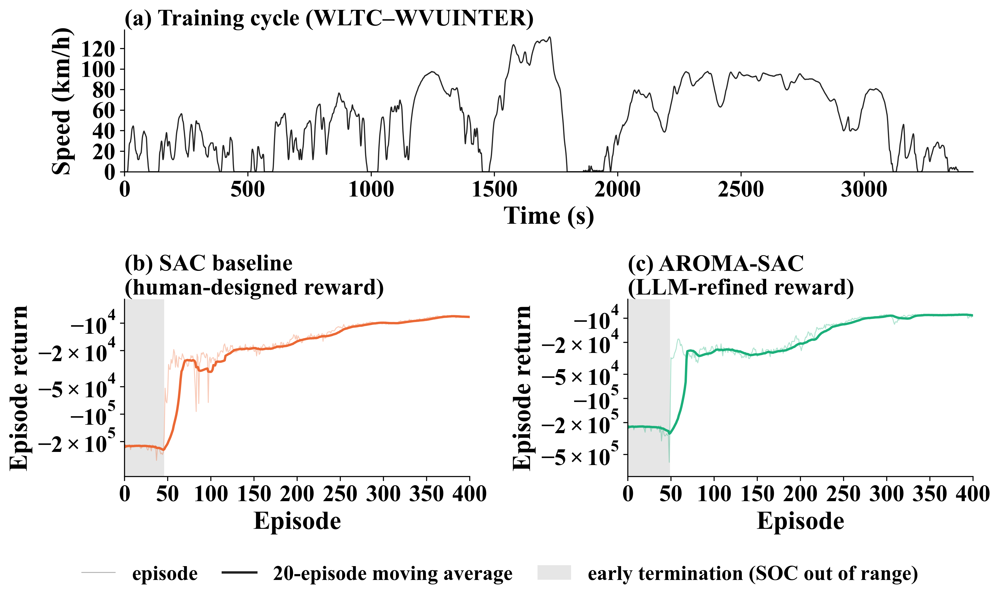

In [6]:
def _curve_ylim(r, lower_pct=20, pad=0.15):
    # The exploratory first episodes are an order of magnitude below the converged return; zoom on the converged part.
    lo, hi = np.nanpercentile(r, lower_pct), np.nanmax(r)
    span = hi - lo
    return lo - pad * span, hi + pad * span


LOG_TICKS = [-m * 10.0 ** e for e in range(6, -2, -1) for m in (5, 2, 1)]


def _sci(x):
    e = int(np.floor(np.log10(abs(x))))
    m = abs(x) / 10 ** e
    return ('$-' if x < 0 else '$') + (f'10^{{{e}}}$' if np.isclose(m, 1) else f'{m:g}\\times10^{{{e}}}$')


from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D

# Bold, enlarged text for Fig. 6 (same style as the other bold paper figures).
for _f in ('timesbd.ttf', 'timesbi.ttf', 'timesi.ttf'):
    _fp = Path('/mnt/c/Windows/Fonts') / _f
    if _fp.exists():
        font_manager.fontManager.addfont(str(_fp))
TRAIN_RC = {'font.size': 18, 'axes.titlesize': 20, 'axes.labelsize': 20, 'xtick.labelsize': 18, 'ytick.labelsize': 18,
            'legend.fontsize': 16, 'font.weight': 'bold', 'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
            'mathtext.fontset': 'custom', 'mathtext.rm': 'Times New Roman:bold',
            'mathtext.it': 'Times New Roman:italic:bold', 'mathtext.bf': 'Times New Roman:bold'}


def training_figure(key='train_r', value='return', yscale=None, name='fig06_training'):
    # value: 'return' = sum of the step rewards of the episode; 'mean_step' = that sum divided by the episode length.
    # yscale: 'log' (full range, log axis), 'linear' (full range), 'zoom' (linear, cut to the converged part).
    yscale = yscale or TRAIN_YSCALE
    with plt.rc_context(TRAIN_RC):
        ylabel = {'return': 'Episode return', 'mean_step': 'Average reward per step'}[value]
        fig = plt.figure(figsize=(11, 6.6))
        gs = fig.add_gridspec(2, 2, height_ratios=[0.8, 1.0])
        ax_cycle = fig.add_subplot(gs[0, :])
        v = cycle_speed_kmh(TRAIN_CYCLE)
        ax_cycle.plot(np.arange(len(v)), v, **SPEED_LINE)
        ax_cycle.set_xlim(0, len(v))
        ax_cycle.set_ylim(0, None)
        ax_cycle.set_xlabel('Time (s)')
        ax_cycle.set_ylabel('Speed (km/h)')
        ax_cycle.xaxis.set_major_locator(MultipleLocator(500))  # original tick spacing
        ax_cycle.yaxis.set_major_locator(MultipleLocator(20))
        panel_tag(ax_cycle, 'a', f'Training cycle ({TRAIN_CYCLE.replace("_", "–")})', fontsize=None)

        titles = {'SAC': 'SAC baseline\n(human-designed reward)', 'AROMA-SAC': 'AROMA-SAC\n(LLM-refined reward)'}
        for i, (m, tag) in enumerate(zip(METHODS, 'bc')):
            ax = fig.add_subplot(gs[1, i])
            t, color = TRAIN[m], STYLE[m]['color']
            y = t[key] / t.steps if value == 'mean_step' else t[key]
            ax.plot(t.index, y, color=color, linewidth=0.7, alpha=0.35, label='episode')
            ax.plot(t.index, y.rolling(SMOOTH_WINDOW, min_periods=1).mean(), color=color, linewidth=1.8,
                    label=f'{SMOOTH_WINDOW}-episode moving average')
            ax.xaxis.set_major_locator(MultipleLocator(50))  # original tick spacing
            ax.set_xlim(0, len(t))
            if yscale == 'log':
                ax.set_yscale('symlog', linthresh=abs(y.max()) / 10.0)
                ax.set_ylim(1.5 * y.min(), y.max() / 1.5)
                ticks = [x for x in LOG_TICKS if ax.get_ylim()[0] <= x <= ax.get_ylim()[1]]
                ax.set_yticks(ticks)
                ax.set_yticklabels([_sci(x) for x in ticks])
                ax.minorticks_off()
                early = t.index[t.steps < t.steps.max()]
                if len(early):
                    ax.axvspan(0, early.max() + 1, color='0.9', linewidth=0, zorder=0, label='early termination (SOC out of range)')
            elif yscale == 'zoom':
                ax.set_ylim(*_curve_ylim(y.values))
                ax.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3), useMathText=True)
            ax.set_xlabel('Episode')
            ax.set_ylabel(ylabel)
            panel_tag(ax, tag, titles.get(m, m), fontsize=None)
        # one shared legend under the panels: in-axes legends cover the curves and tick labels at this text size
        handles = [Line2D([], [], color=INK, linewidth=0.7, alpha=0.35, label='episode'),
                   Line2D([], [], color=INK, linewidth=1.8, label=f'{SMOOTH_WINDOW}-episode moving average')]
        if yscale == 'log':
            handles.append(Patch(facecolor='0.9', edgecolor='none', label='early termination (SOC out of range)'))
        fig.legend(handles=handles, ncol=len(handles), loc='lower center', bbox_to_anchor=(0.5, 0.0), frameon=False,
                   handlelength=1.6, columnspacing=1.2)
        fig.tight_layout(rect=(0, 0.07, 1, 1))
        save_fig(name, fig)
        plt.show()

training_figure()

### Alternative: average reward per step, linear axis

Same data as (b) and (c), divided by the number of steps of each episode (3441 for a complete episode, fewer when the episode
terminated early) and drawn on a linear axis over the full range.

[fig] seed1_gpt_iter3__fig06_training_mean_step_reward -> paper_figures/


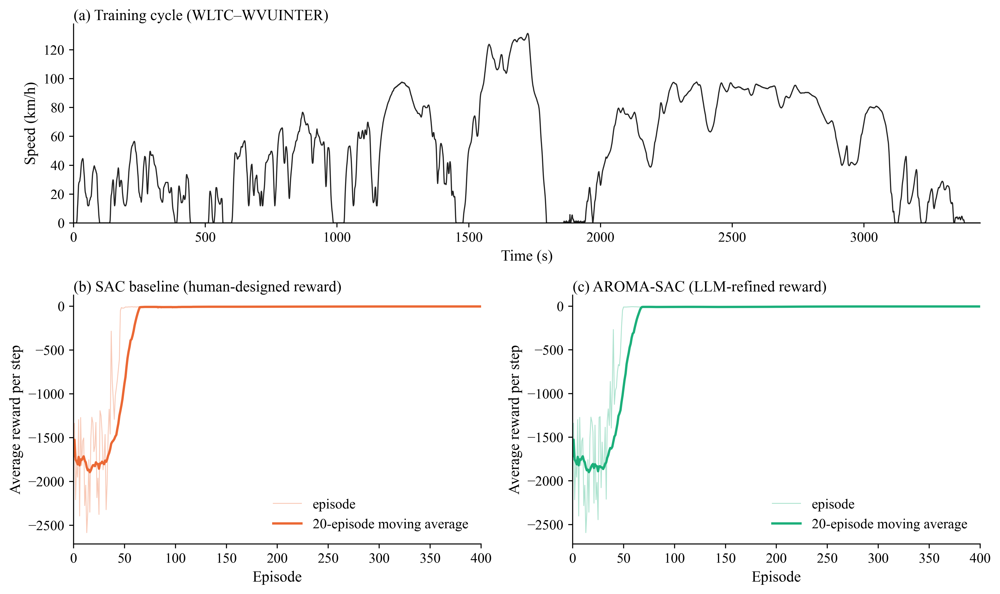

SAC        mean step reward: ep0-19  -1815.6, ep50-99  -8.67, ep300-349  -2.77, ep350-399  -2.47
AROMA-SAC  mean step reward: ep0-19  -1820.3, ep50-99  -7.74, ep300-349  -2.77, ep350-399  -2.66


In [7]:
training_figure(value='mean_step', yscale='linear', name='fig06_training_mean_step_reward')
for m, t in TRAIN.items():
    y = t.train_r / t.steps
    print(f'{m:10s} mean step reward: ep0-19 {y[:20].mean():8.1f}, ep50-99 {y[50:100].mean():6.2f}, ep300-349 {y[300:350].mean():6.2f}, ep350-399 {y[350:].mean():6.2f}')

## Fig. 7 — evaluation driving cycles

[fig] seed1_gpt_iter3__fig07_evaluation_cycles -> paper_figures/


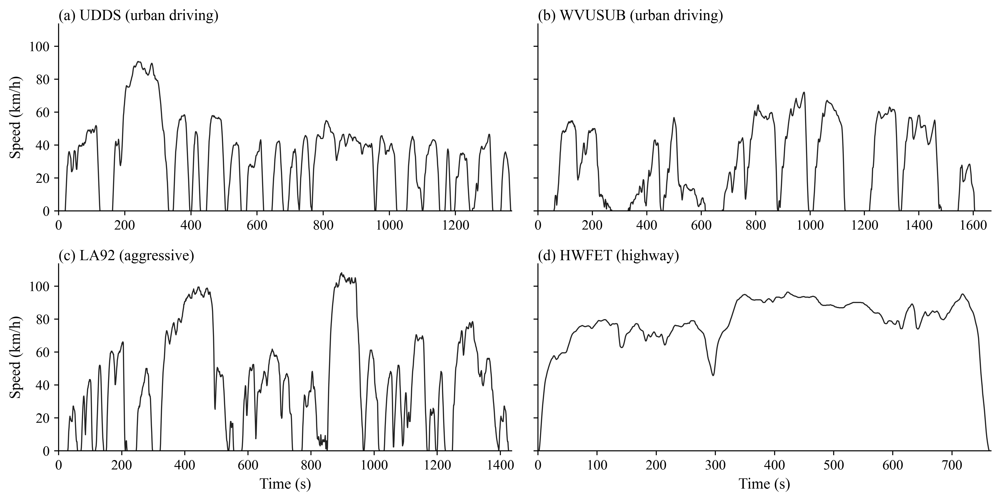

In [8]:
def cycles_figure():
    fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharey=True)
    for ax, c, tag in zip(axes.ravel(), CYCLES, 'abcd'):
        v = cycle_speed_kmh(c)
        t = np.arange(len(v))
        ax.plot(t, v, **SPEED_LINE)
        ax.set_xlim(0, len(v))
        dist = v.sum() / 3.6 * DT / 1000.0
        #ax.text(0.985, 0.95, f'{len(v)} s, {dist:.1f} km\nmean {v.mean():.1f}, max {v.max():.1f} km/h', transform=ax.transAxes,
        #        ha='right', va='top', fontsize=10, color=INK, bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))
        panel_tag(ax, tag, f'{c} ({CYCLE_CLASS[c]})')
    axes[0, 0].set_ylim(0, None)
    for ax in axes[-1]:
        ax.set_xlabel('Time (s)')
    for ax in axes[:, 0]:
        ax.set_ylabel('Speed (km/h)')
    fig.tight_layout()
    save_fig('fig07_evaluation_cycles', fig)
    plt.show()


cycles_figure()

## Fig. 9–12 — time-series comparison on each evaluation cycle

(a) vehicle speed, (b) battery SOC (grey band: charge-sustaining range SOC0 ± `CS_TOL`), (c) cumulative H$_2$ consumed by the fuel cell (raw, not SOC-corrected), (d) fuel-cell power
applied by the plant, (e) battery power delivered (positive = discharge).

[fig] seed1_gpt_iter3__fig09_timeseries_UDDS -> paper_figures/


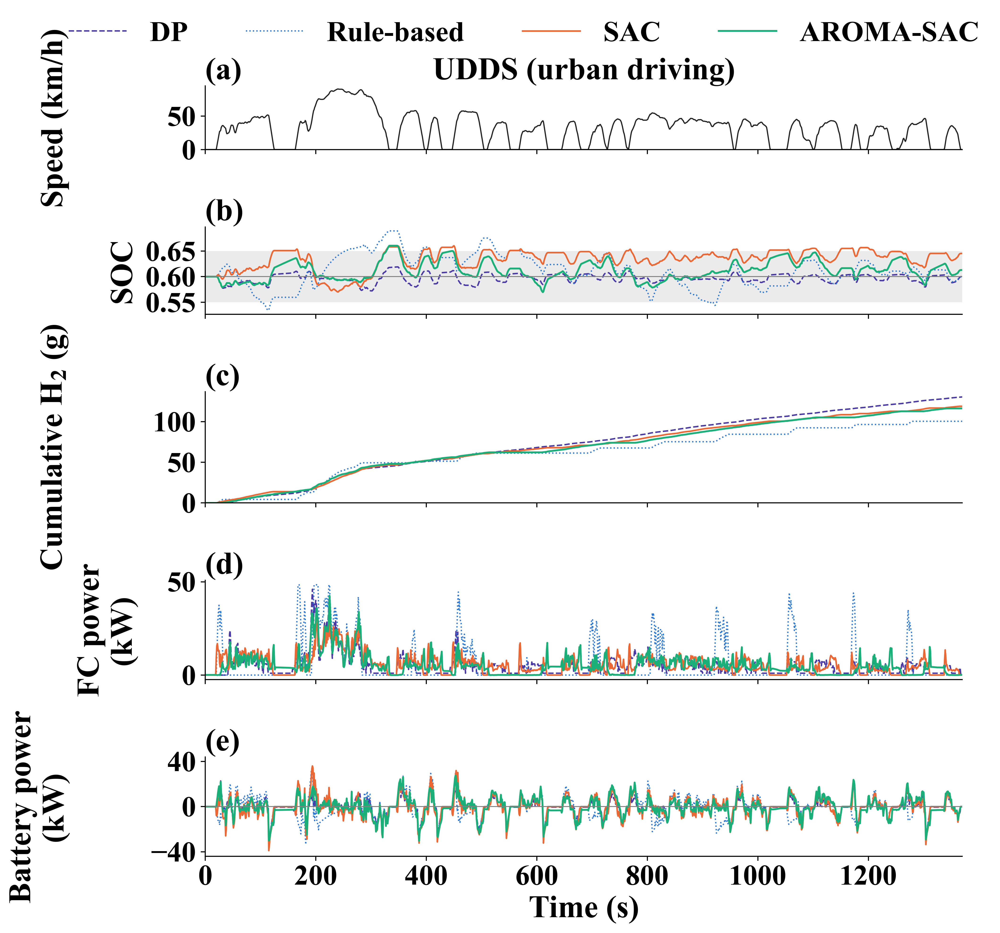

[fig] seed1_gpt_iter3__fig10_timeseries_WVUSUB -> paper_figures/


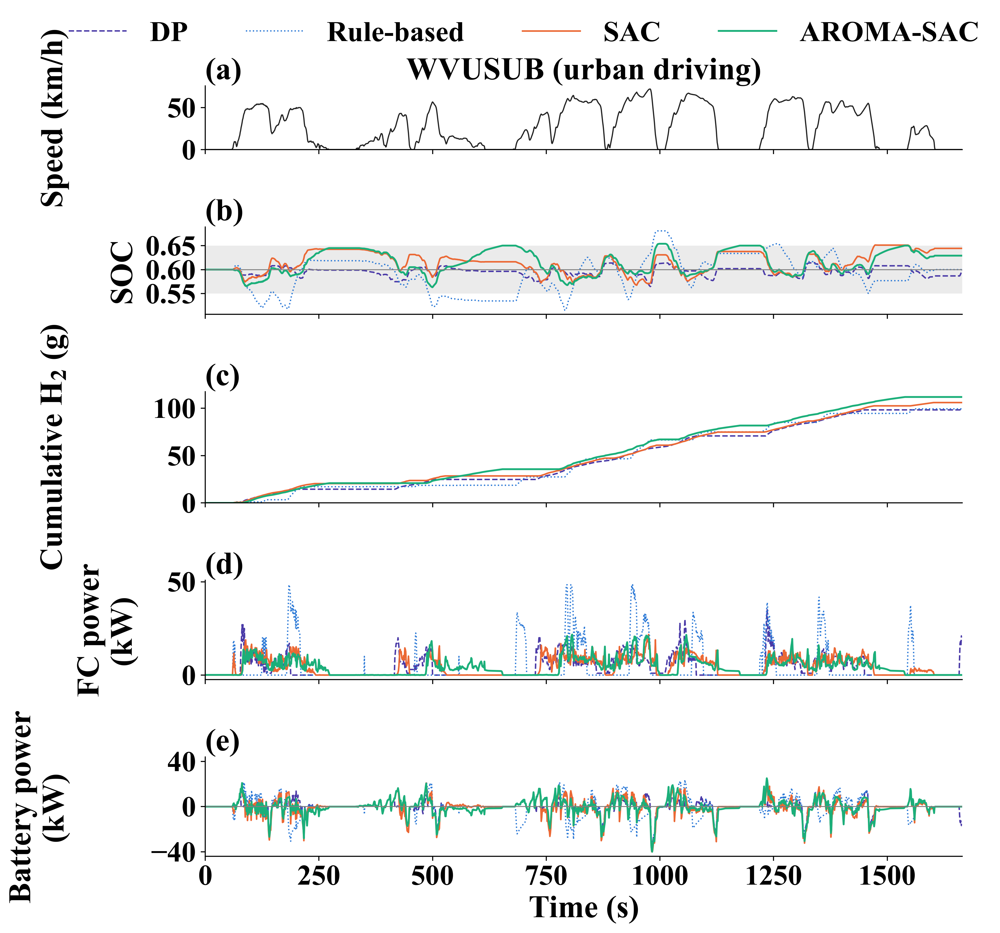

[fig] seed1_gpt_iter3__fig11_timeseries_LA92 -> paper_figures/


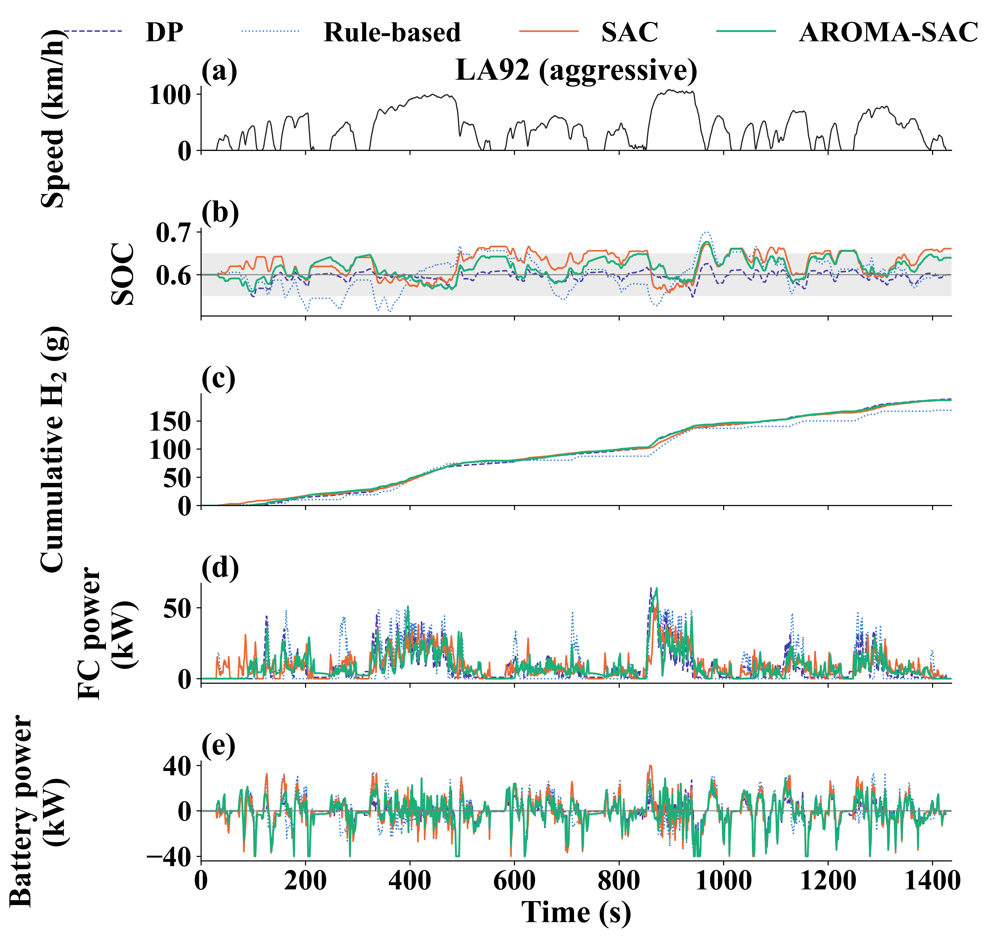

[fig] seed1_gpt_iter3__fig12_timeseries_HWFET -> paper_figures/


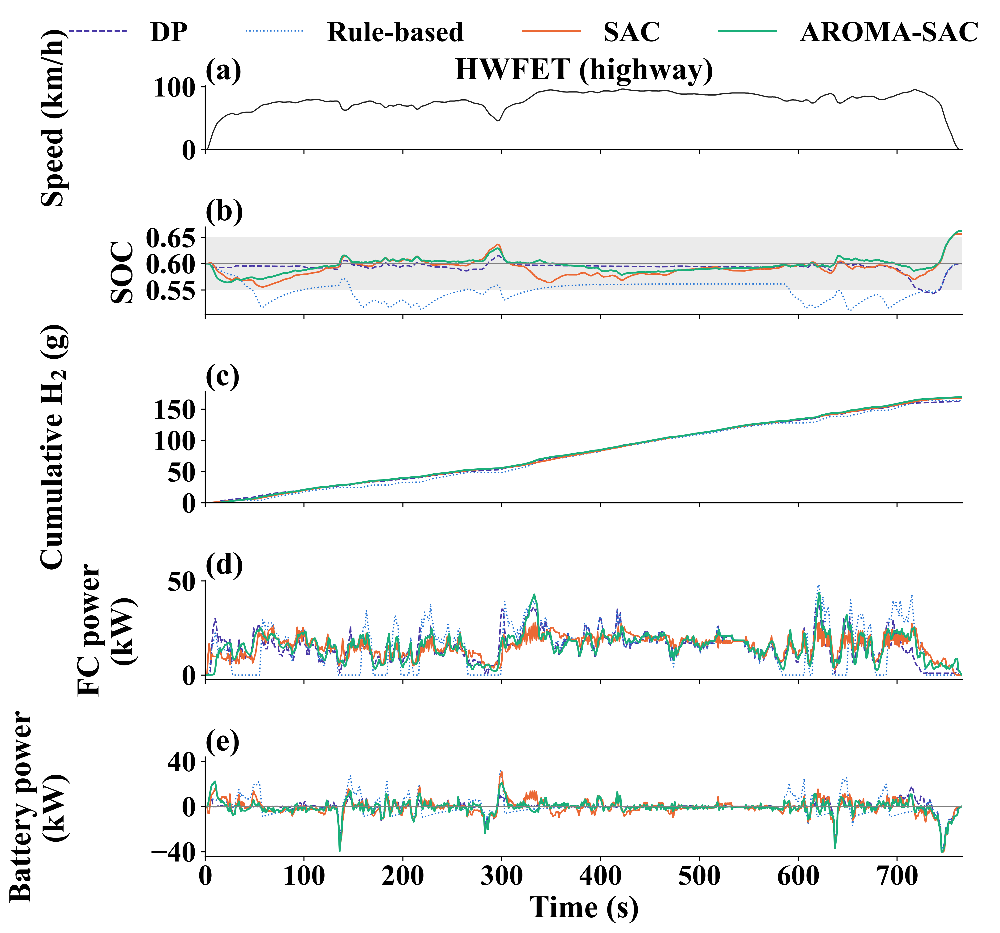

In [9]:
FIG_NUMBER = {'UDDS': 9, 'WVUSUB': 10, 'LA92': 11, 'HWFET': 12}

# Fig. 5-8 text: 1 pt larger than the notebook default and bold.
for _f in ('timesbd.ttf', 'timesbi.ttf', 'timesi.ttf'):
    _fp = Path('/mnt/c/Windows/Fonts') / _f
    if _fp.exists():
        font_manager.fontManager.addfont(str(_fp))
TS_RC = {'font.size': 24, 'axes.labelsize': 24, 'xtick.labelsize': 22, 'ytick.labelsize': 22,
         'legend.fontsize': 22, 'font.weight': 'bold', 'axes.labelweight': 'bold',
         'axes.titleweight': 'bold', 'mathtext.default': 'bf'}


from matplotlib.ticker import MultipleLocator


def stagger_ylabels(fig, axes, pad_pt=6, gap_pt=6):
    # Two label columns on the left: (b), (d) sit right next to the tick labels, (a), (c), (e) one column further out,
    # so a y label longer than its panel passes beside its neighbours' labels instead of running into them.
    from matplotlib.transforms import blended_transform_factory
    r = fig.canvas.get_renderer()
    to_fig = fig.transFigure.inverted()
    def place(group, x_px):
        xf = to_fig.transform((x_px, 0))[0]
        for ax in group:
            ax.yaxis.set_label_coords(xf, 0.5, transform=blended_transform_factory(fig.transFigure, ax.transAxes))
    fig.canvas.draw()
    tick_left = min(t.get_window_extent(r).x0 for ax in axes for t in ax.get_yticklabels() if t.get_text())
    inner, outer = axes[1::2], axes[0::2]
    place(inner, tick_left - pad_pt * fig.dpi / 72)
    fig.canvas.draw()
    inner_left = min(ax.yaxis.label.get_window_extent(r).x0 for ax in inner)
    place(outer, inner_left - gap_pt * fig.dpi / 72)


def timeseries_figure(cycle):
    tr = eval_traces(cycle)
    order = REFERENCES + METHODS  # references underneath
    v = cycle_speed_kmh(cycle)
    n = len(v)
    t = np.arange(n)
    fig, axes = plt.subplots(5, 1, figsize=(10, 10.2), sharex=True, gridspec_kw=dict(height_ratios=[0.8, 1.1, 1.4, 1.25, 1.25]))
    axes[0].plot(t, v, **SPEED_LINE)
    axes[0].set_ylim(0, None)
    axes[0].set_ylabel('Speed (km/h)')
    for m in order:
        d, st = tr[m], STYLE[m]
        assert len(d['SOC']) == n, (cycle, m, len(d['SOC']), n)
        h2 = np.r_[0.0, np.cumsum(d['h2_fcs']) * DT]
        axes[1].plot(np.r_[0, t + 1], np.r_[SOC0, d['SOC']], label=m, **st)
        axes[2].plot(np.r_[0, t + 1], h2, label=m, **st)
        axes[3].plot(t, d['fc_applied_kw'], label=m, **st)
        axes[4].plot(t, d['battery_delivered_kw'], label=m, **st)
    axes[1].axhline(SOC0, color='0.5', linewidth=0.7)
    axes[1].axhspan(SOC0 - CS_TOL, SOC0 + CS_TOL, color='0.92', linewidth=0, zorder=0)
    axes[1].set_ylabel('SOC')
    axes[2].set_ylabel('Cumulative H$_2$ (g)')
    axes[2].set_ylim(0, None)
    axes[2].yaxis.set_major_locator(MultipleLocator(50))
    axes[3].set_ylabel('FC power\n(kW)')
    axes[4].axhline(0.0, color='0.5', linewidth=0.7)
    axes[4].set_ylabel('Battery power\n(kW)')
    axes[4].yaxis.set_major_locator(MultipleLocator(40))
    _lo, _hi = axes[4].get_ylim()
    axes[4].set_ylim(min(_lo, -44.0), max(_hi, 44.0))  # keep the ±40 kW ticks inside the axis
    axes[4].set_xlabel('Time (s)')
    axes[4].set_xlim(0, n)
    for ax, tag in zip(axes, 'abcde'):
        ax.set_title(f'({tag})', loc='left', fontsize=24, pad=3)
    axes[0].set_title(f'{cycle} ({CYCLE_CLASS[cycle]})', fontsize=24, pad=3)
    fig.legend(*axes[1].get_legend_handles_labels(), ncol=len(order), loc='upper center', bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    stagger_ylabels(fig, axes)
    save_fig(f'fig{FIG_NUMBER[cycle]:02d}_timeseries_{cycle}', fig)
    plt.show()


for c in CYCLES:
    with plt.rc_context(TS_RC):
        timeseries_figure(c)

## Fig. 13 — operating cost per 100 km

Same economics as `paper_figs_multi_seed.ipynb` (Figures 4 / 4b): **fuel cost** = SOC-corrected equivalent H$_2$ × `H2_PRICE`;
**degradation cost** = the part of the FC system (`FC_NET_KW` × `FC_COST_PER_KW`) and of the battery pack (`BATT_KWH` ×
`BATT_COST_PER_KWH`) used up by the wear of the distance, i.e. component cost × SOH loss per km / end-of-life loss;
**total** = fuel + degradation, all in USD per 100 km. The per-cycle values equal `total_usd` of the evaluation tables (checked).
"4-cycle mix" = equal distance on each cycle (mean of the per-km rates), as in the multi-seed figures.

`COST` holds one row per method and cycle (plus the mix), `COST_TABLE` the values on every evaluation cycle and the 4-cycle mix,
with the change of AROMA-SAC against SAC (saved as CSV and as a booktabs LaTeX table for the paper).
On LA92 / HWFET the SAC baseline (and on HWFET AROMA-SAC) ends above the CS band, so its fuel cost there is credited for the
stored charge; the LaTeX table marks those fuel costs with a dagger.

In [10]:
COST_METHODS = REFERENCES + METHODS  # bar order: DP, rule-based, SAC, AROMA-SAC
FC_COST = FC_NET_KW * FC_COST_PER_KW
BATT_COST = BATT_KWH * BATT_COST_PER_KWH
COST_PARTS = [('total_cost', 'Total operating cost'), ('h2_cost', 'Fuel cost'), ('deg_cost', 'Degradation cost')]


def economics(rate):
    # rate: eq (g/km), fc_km and bt_km (SOH loss per km) -> cost in USD per 100 km
    e = rate.copy()
    e['h2_cost'] = e['eq'] / 1000.0 * H2_PRICE * 100.0
    e['fc_cost'] = FC_COST * e.fc_km / FC_EOL_LOSS * 100.0
    e['bt_cost'] = BATT_COST * e.bt_km / BATT_EOL_LOSS * 100.0
    e['deg_cost'] = e.fc_cost + e.bt_cost
    e['total_cost'] = e.h2_cost + e.deg_cost
    return e


_r = []
for c in CYCLES:
    for m in COST_METHODS:
        r = metric_row(m, c)
        _r.append({'method': m, 'cycle': c, 'eq': r.equivalent_h2_g_per_km, 'fc_km': r.fc_soh_loss / r.distance_km,
                   'bt_km': r.battery_soh_loss / r.distance_km, 'cs': abs(r.final_soc - SOC0) <= CS_TOL, 'check': r.total_usd})
RATE = pd.DataFrame(_r)
_per_cycle = economics(RATE)
assert np.allclose(_per_cycle.total_cost, _per_cycle.check, rtol=1e-6), 'cost model differs from the evaluation tables'
_mix = economics(RATE.groupby('method')[['eq', 'fc_km', 'bt_km']].mean().reset_index()).assign(cycle='4-cycle mix')
COST = pd.concat([_per_cycle, _mix], ignore_index=True).drop(columns=['check', 'cs'])
NON_CS = {(r.method, r.cycle) for r in RATE.itertuples() if not r.cs}  # fuel cost credited for the stored charge

TABLE_GROUPS = CYCLES + ['4-cycle mix']
TABLE_ROWS = COST_PARTS + [('fc_cost', 'of which FC degradation'), ('bt_cost', 'of which battery degradation')]
_rows = {}
for group in TABLE_GROUPS:
    g = COST[COST.cycle == group].set_index('method')
    for key, label in TABLE_ROWS:
        row = {m: g.loc[m, key] for m in COST_METHODS}
        row['AROMA-SAC vs SAC (USD)'] = g.loc['AROMA-SAC', key] - g.loc['SAC', key]
        row['AROMA-SAC vs SAC (%)'] = (g.loc['AROMA-SAC', key] / g.loc['SAC', key] - 1) * 100
        _rows[(group, label)] = row
COST_TABLE = pd.DataFrame(_rows).T
COST_TABLE.index.names = ['cycle', 'cost (USD/100 km)']


def cost_table_latex(t):
    # paper table: 2 decimals, signed change, a dagger on the fuel cost of a rollout that is not charge sustaining
    f = pd.DataFrame(index=t.index, columns=t.columns, dtype=object)
    for (group, label), r in t.iterrows():
        for m in COST_METHODS:
            dag = r'$^\dagger$' if label == 'Fuel cost' and (m, group) in NON_CS else ''
            f.loc[(group, label), m] = f'{r[m]:.2f}{dag}'
        f.loc[(group, label), 'AROMA-SAC vs SAC (USD)'] = f'{r["AROMA-SAC vs SAC (USD)"]:+.2f}'.replace('-', '$-$')
        f.loc[(group, label), 'AROMA-SAC vs SAC (%)'] = f'{r["AROMA-SAC vs SAC (%)"]:+.1f}'.replace('-', '$-$')
    f.columns = COST_METHODS + [r'$\Delta$ (USD)', r'$\Delta$ (\%)']
    f.index = f.index.set_names(['Cycle', 'Cost (USD/100 km)'])
    tex = f.to_latex(multirow=True, column_format='ll' + 'r' * len(f.columns), escape=False,
                      caption=('Operating cost per 100 km on the evaluation cycles (seed 1). $\\Delta$: AROMA-SAC against SAC. '
                               f'$^\\dagger$ not charge sustaining ($|\\Delta \\mathrm{{SOC}}| > {CS_TOL}$): the fuel cost is '
                               'credited for the charge stored in the battery.'),
                      label='tab:operating_cost_seed1')
    # booktabs rules between the cycle blocks (needs \\usepackage{booktabs, multirow})
    rule = '\\cline{1-%d}\n' % (f.index.nlevels + f.shape[1])
    return tex.replace(rule + '\\bottomrule', '\\bottomrule').replace(rule, '\\midrule\n')


print('not charge sustaining (fuel cost credited for stored charge):', ', '.join(f'{m} {c}' for m, c in sorted(NON_CS)) or 'none')
if SAVE_FIGS:
    FIG_OUTDIR.mkdir(parents=True, exist_ok=True)
    COST_TABLE.to_csv(FIG_OUTDIR / f'{FIG_PREFIX}__cost_table.csv')
    (FIG_OUTDIR / f'{FIG_PREFIX}__cost_table.tex').write_text(cost_table_latex(COST_TABLE))
COST_TABLE.round(2)


not charge sustaining (fuel cost credited for stored charge): AROMA-SAC HWFET, SAC HWFET, SAC LA92


DP  Rule-based     SAC  \
cycle       cost (USD/100 km)                                         
UDDS        Total operating cost          24.18      162.67  197.45   
            Fuel cost                      7.65        5.90    6.73   
            Degradation cost              16.52      156.77  190.72   
            of which FC degradation       11.14      148.10  182.81   
            of which battery degradation   5.38        8.67    7.91   
WVUSUB      Total operating cost          60.55      170.57  112.66   
            Fuel cost                      5.84        5.81    5.97   
            Degradation cost              54.71      164.76  106.69   
            of which FC degradation       50.04      155.95   99.84   
            of which battery degradation   4.67        8.81    6.85   
LA92        Total operating cost          23.47      202.78  199.30   
            Fuel cost                      8.36        7.49    8.05   
            Degradation cost              15.11      195.30  191.26   
            of which FC degradation        8.29      185.32  180.95   
            of which battery degradation   6.81        9.97   10.31   
HWFET       Total operating cost          15.62       98.96   17.63   
            Fuel cost                      6.89        6.94    6.91   
            Degradation cost               8.73       92.02   10.72   
            of which FC degradation        7.28       89.27    8.12   
            of which battery degradation   1.44        2.75    2.60   
4-cycle mix Total operating cost          30.95      158.75  131.76   
            Fuel cost                      7.19        6.53    6.91   
            Degradation cost              23.77      152.21  124.85   
            of which FC degradation       19.19      144.66  117.93   
            of which battery degradation   4.58        7.55    6.92   

                                          AROMA-SAC  AROMA-SAC vs SAC (USD)  \
cycle       cost (USD/100 km)                                                 
UDDS        Total operating cost              85.82                 -111.63   
            Fuel cost                          6.76                    0.03   
            Degradation cost                  79.07                 -111.66   
            of which FC degradation           71.15                 -111.67   
            of which battery degradation       7.92                    0.01   
WVUSUB      Total operating cost              63.69                  -48.97   
            Fuel cost                          6.38                    0.41   
            Degradation cost                  57.31                  -49.38   
            of which FC degradation           50.45                  -49.38   
            of which battery degradation       6.86                    0.00   
LA92        Total operating cost              76.19                 -123.12   
            Fuel cost                          8.11                    0.07   
            Degradation cost                  68.08                 -123.18   
            of which FC degradation           59.27                 -121.68   
            of which battery degradation       8.81                   -1.50   
HWFET       Total operating cost              16.41                   -1.22   
            Fuel cost                          6.95                    0.04   
            Degradation cost                   9.46                   -1.26   
            of which FC degradation            7.29                   -0.83   
            of which battery degradation       2.18                   -0.43   
4-cycle mix Total operating cost              60.53                  -71.23   
            Fuel cost                          7.05                    0.14   
            Degradation cost                  53.48                  -71.37   
            of which FC degradation           47.04                  -70.89   
            of which battery degradation       6.44                   -0.

### Fig. 13 (a) total cost split into fuel and degradation, (b–d) total / fuel / degradation cost on each cycle

(a) 4-cycle mix: fuel cost (solid), FC degradation (cross-hatched) and battery degradation (dotted) stacked; the number above
each bar is the total, with the change against SAC for AROMA-SAC. The y axis is broken only when the rule-based total
exceeds twice the largest total of the other methods. (b–d) one panel per cost, bars per cycle and for the 4-cycle mix; the
percentage is AROMA-SAC against SAC. Total and degradation cost are on a log axis (rule-based and DP differ by an order of
magnitude); a hollow bar marks a rollout that ends outside the CS band (its fuel cost is credited for stored charge).

[fig] seed1_gpt_iter3__fig13a_operating_cost_stack -> paper_figures/


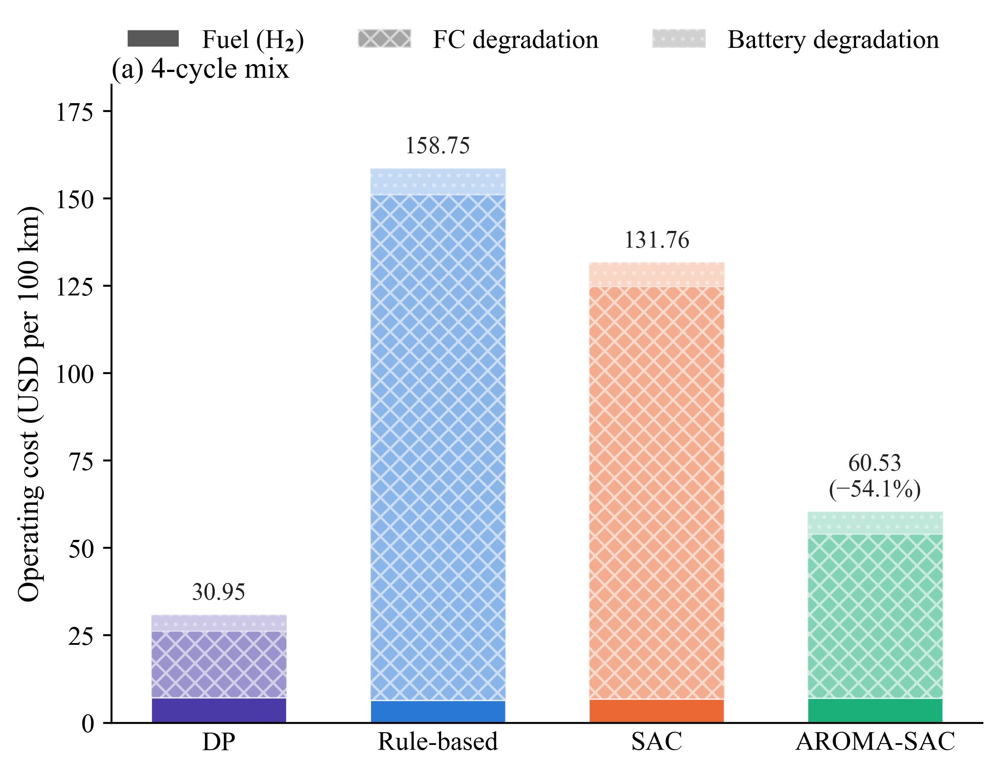

[fig] seed1_gpt_iter3__fig13bcd_operating_cost_by_cycle -> paper_figures/


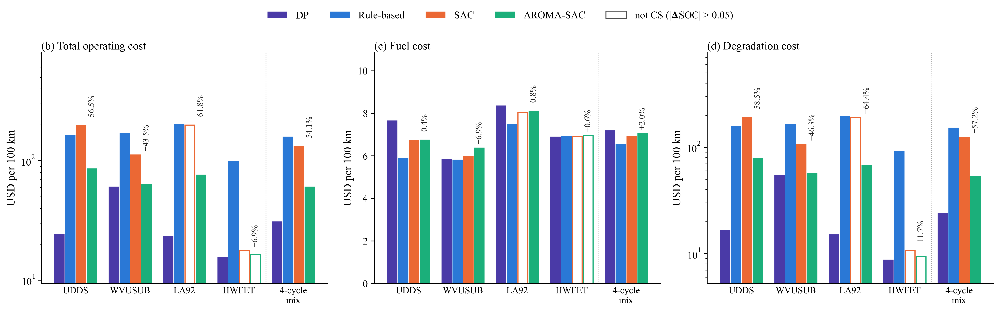

In [11]:
def _pct(v):
    return f'{v:+.1f}%'.replace('-', '−')


def cost_stack_figure():
    mix = COST[COST.cycle == '4-cycle mix'].set_index('method').loc[COST_METHODS]
    tot = mix.total_cost
    others = tot.drop('Rule-based').max()
    broken = tot.max() > 2.0 * others  # break only when the rule-based total dwarfs the others
    low_top = others * 1.45 if broken else tot.max() * 1.15
    if broken:
        fig, (hi, lo) = plt.subplots(2, 1, figsize=(6.4, 5.2), sharex=True, gridspec_kw=dict(height_ratios=[1, 3.2], hspace=0.06))
        panels = [hi, lo]
    else:
        fig, lo = plt.subplots(figsize=(6.4, 4.6))
        panels = [lo]
    for ax in panels:
        for j, m in enumerate(COST_METHODS):
            r, col = mix.loc[m], STYLE[m]['color']
            ax.bar(j, r.h2_cost, 0.62, color=col, edgecolor='white', linewidth=0.6, zorder=2)
            ax.bar(j, r.fc_cost, 0.62, bottom=r.h2_cost, color=col, alpha=0.55, hatch='xxx', edgecolor='white', linewidth=0.6, zorder=2)
            ax.bar(j, r.bt_cost, 0.62, bottom=r.h2_cost + r.fc_cost, color=col, alpha=0.28, hatch='...', edgecolor='white',
                   linewidth=0.6, zorder=2)
        ax.tick_params(axis='x', length=0)
    for j, m in enumerate(COST_METHODS):
        label = f'{tot[m]:.2f}' + (f'\n({_pct((tot[m] / tot["SAC"] - 1) * 100)})' if m == 'AROMA-SAC' else '')
        ax = panels[0] if (broken and tot[m] > low_top) else lo
        ax.annotate(label, (j, tot[m]), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=10, color=INK)
    lo.set_ylim(0, low_top)
    if broken:
        hi.set_ylim(tot.max() * 0.78, tot.max() * 1.22)
        hi.spines['bottom'].set_visible(False)
        kw = dict(marker=[(-1, -0.5), (1, 0.5)], markersize=9, linestyle='none', color=INK, mec=INK, mew=0.9, clip_on=False)
        hi.plot([0], [0], transform=hi.transAxes, **kw)
        lo.plot([0], [1], transform=lo.transAxes, **kw)
    lo.set_xticks(range(len(COST_METHODS)))
    lo.set_xticklabels(COST_METHODS)
    lo.set_ylabel('Operating cost (USD per 100 km)')
    handles = [Patch(facecolor='0.35', edgecolor='white', label='Fuel (H$_2$)'),
               Patch(facecolor='0.35', alpha=0.55, hatch='xxx', edgecolor='white', label='FC degradation'),
               Patch(facecolor='0.35', alpha=0.28, hatch='...', edgecolor='white', label='Battery degradation')]
    fig.legend(handles=handles, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.subplots_adjust(top=0.9)
    panel_tag(panels[0], 'a', '4-cycle mix')
    save_fig('fig13a_operating_cost_stack', fig)
    plt.show()


def cost_by_cycle_figure():
    groups = CYCLES + ['4-cycle mix']
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    width = 0.8 / len(COST_METHODS)
    for ax, tag, (key, title) in zip(axes, 'bcd', COST_PARTS):
        log = key != 'h2_cost'
        for j, m in enumerate(COST_METHODS):
            for gi, g in enumerate(groups):
                v = COST[(COST.cycle == g) & (COST.method == m)][key].iloc[0]
                x = gi + (j - (len(COST_METHODS) - 1) / 2) * width
                noncs = g in CYCLES and not RATE[(RATE.cycle == g) & (RATE.method == m)].cs.iloc[0]
                ax.bar(x, v, width * 0.9, color='white' if noncs else STYLE[m]['color'], edgecolor=STYLE[m]['color'],
                       linewidth=1.2 if noncs else 0.6, zorder=2)
        j = COST_METHODS.index('AROMA-SAC')
        for gi, g in enumerate(groups):
            a = COST[(COST.cycle == g) & (COST.method == 'AROMA-SAC')][key].iloc[0]
            s = COST[(COST.cycle == g) & (COST.method == 'SAC')][key].iloc[0]
            x = gi + (j - (len(COST_METHODS) - 1) / 2) * width
            ax.annotate(_pct((a / s - 1) * 100), (x, max(a, s)), xytext=(0, 4), textcoords='offset points', ha='center',
                        va='bottom', fontsize=9, rotation=90, color=INK)
        if log:
            ax.set_yscale('log')
            ax.set_ylim(COST[key].min() * 0.6, COST[key].max() * 4)
        else:
            ax.set_ylim(0, COST[key].max() * 1.3)
        ax.axvline(len(CYCLES) - 0.5, color='0.6', linewidth=0.8, linestyle=':')
        ax.set_xticks(range(len(groups)))
        ax.set_xticklabels(CYCLES + ['4-cycle\nmix'], fontsize=10)
        ax.tick_params(axis='x', length=0)
        ax.set_ylabel('USD per 100 km')
        panel_tag(ax, tag, title)
    handles = [Patch(facecolor=STYLE[m]['color'], edgecolor='white', label=m) for m in COST_METHODS]
    handles.append(Patch(facecolor='white', edgecolor='0.3', label=f'not CS (|$\\Delta$SOC| > {CS_TOL})'))
    fig.legend(handles=handles, ncol=len(handles), loc='upper center', bbox_to_anchor=(0.5, 1.02), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    save_fig('fig13bcd_operating_cost_by_cycle', fig)
    plt.show()


cost_stack_figure()
cost_by_cycle_figure()

## Fig. S1–S4 — FC operating points on the efficiency curve

Same figures as `paper_figs_multi_seed.ipynb` (Figure 3 and Figures S1–S4), drawn for seed 1 with AROMA-SAC = GPT iteration 3.
The grey line is the FC system efficiency map against stack power; each dot is one FC-on second of the rollout (`P_fc`, `fce_eff`).
The label gives the trip-average operating efficiency (FC net energy over H$_2$ energy, the same value used in the equivalent-fuel
conversion) and the FC-on time share. DP and rule-based do not depend on the seed.

Overview first: one panel per method (rows: DP, rule-based, baseline SAC, AROMA-SAC) and cycle (columns).

[fig] seed1_gpt_iter3__fc_efficiency_map_seed1 -> paper_figures/


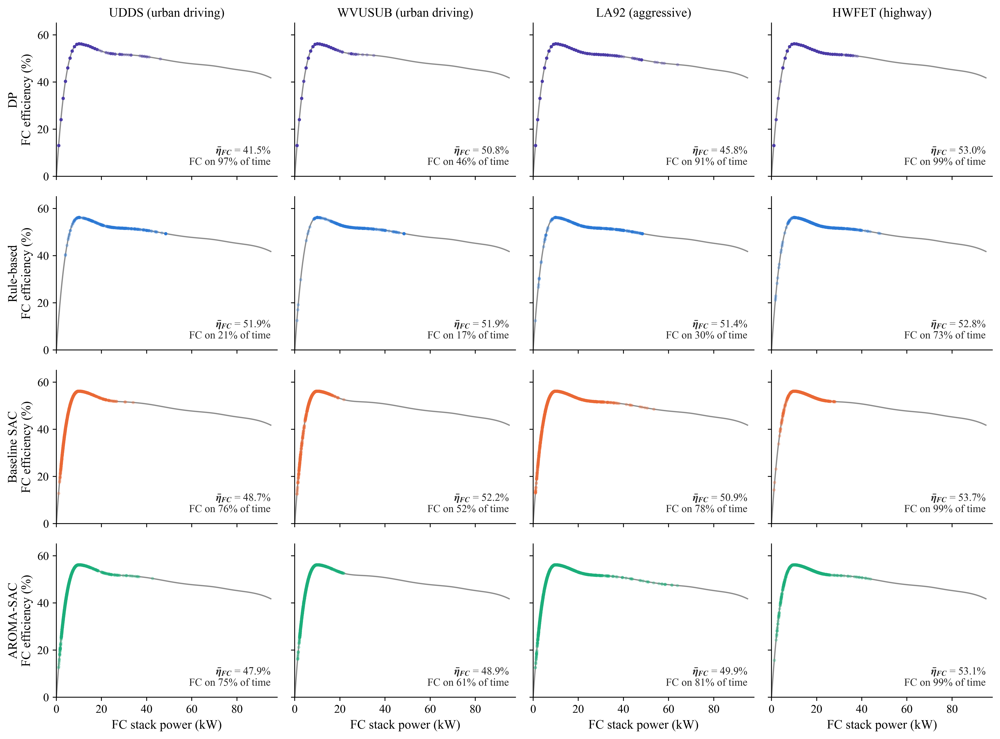

In [12]:
FC_MAP_DIR = ROOT / 'project-data/FCHEV_data'
_p = np.asarray(scio.loadmat(FC_MAP_DIR / 'P_fc_stack_nexo.mat')['P_fc_stack'], dtype=float).reshape(-1)
_e = np.asarray(scio.loadmat(FC_MAP_DIR / 'Eff_fc_nexo.mat')['Eff_fc'], dtype=float).reshape(-1)
_ok = np.isfinite(_p) & np.isfinite(_e)
_order = np.argsort(_p[_ok])
FC_CURVE_P, FC_CURVE_EFF = _p[_ok][_order], _e[_ok][_order] * 100.0

FC_PANELS = [('DP', 'DP'), ('Rule-based', 'Rule-based'), ('SAC', 'Baseline SAC'), ('AROMA-SAC', 'AROMA-SAC')]


def fc_operating_points(d):
    # FC-on samples: stack power (kW), system efficiency (%), and the trip-average operating efficiency (%)
    p, eff = d['P_fc'], d['fce_eff']
    n = min(len(p), len(eff))
    p, eff = p[:n], eff[:n]
    on = np.isfinite(p) & np.isfinite(eff) & (p > 0.0) & (eff > 0.0)
    w = d['P_fce'][:n][on] if 'P_fce' in d else p[on]  # net power weights the trip average
    trip_eff = 100.0 * w.sum() / (w / eff[on]).sum()
    return p[on], eff[on] * 100.0, trip_eff, 100.0 * on.sum() / n


def fc_efficiency_map_figure():
    data = {c: eval_traces(c) for c in CYCLES}
    fig, axes = plt.subplots(len(FC_PANELS), len(CYCLES), figsize=(3.3 * len(CYCLES), 2.45 * len(FC_PANELS)),
                             sharex=True, sharey=True)
    x_max = max(FC_CURVE_P.max(), max(d['P_fc'].max() for c in CYCLES for d in data[c].values())) * 1.03
    for i, (m, title) in enumerate(FC_PANELS):
        for j, c in enumerate(CYCLES):
            ax = axes[i, j]
            p, eff, trip_eff, on_pct = fc_operating_points(data[c][m])
            ax.plot(FC_CURVE_P, FC_CURVE_EFF, color='0.55', linewidth=1.2, zorder=1)
            ax.scatter(p, eff, s=9, color=STYLE[m]['color'], alpha=0.35, linewidths=0, zorder=2)
            ax.text(0.97, 0.06, f'$\\bar{{\\eta}}_{{FC}}$ = {trip_eff:.1f}%\nFC on {on_pct:.0f}% of time', transform=ax.transAxes,
                    ha='right', va='bottom', fontsize=10, color=INK)
            ax.set_xlim(0, x_max)
            ax.set_ylim(0, 65)
            if i == 0:
                ax.set_title(f'{c} ({CYCLE_CLASS[c]})', fontsize=12)
            if j == 0:
                ax.set_ylabel(f'{title}\nFC efficiency (%)')
            if i == len(FC_PANELS) - 1:
                ax.set_xlabel('FC stack power (kW)')
    fig.tight_layout()
    fig.align_ylabels(axes[:, 0])
    save_fig(f'fc_efficiency_map_seed{SEED}', fig)
    plt.show()


fc_efficiency_map_figure()

### Fig. S1–S4 — one figure per cycle

One 2 × 2 figure per evaluation cycle, titled with the cycle name: (a) DP, (b) rule-based, (c) baseline SAC, (d) AROMA-SAC.

Figures S1-S4: seed 1, AROMA-SAC = GPT run iteration 3 (gpt_seed1_iter003_ep399)
[fig] seed1_gpt_iter3__figS1_fc_operating_points_seed1_UDDS -> paper_figures/


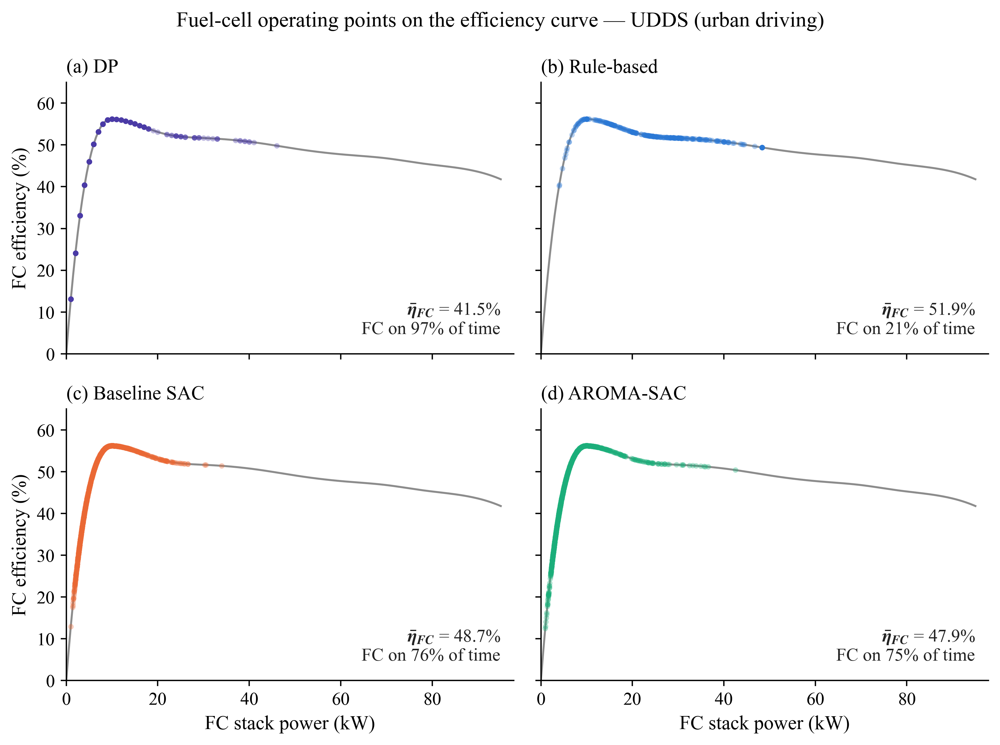

[fig] seed1_gpt_iter3__figS2_fc_operating_points_seed1_WVUSUB -> paper_figures/


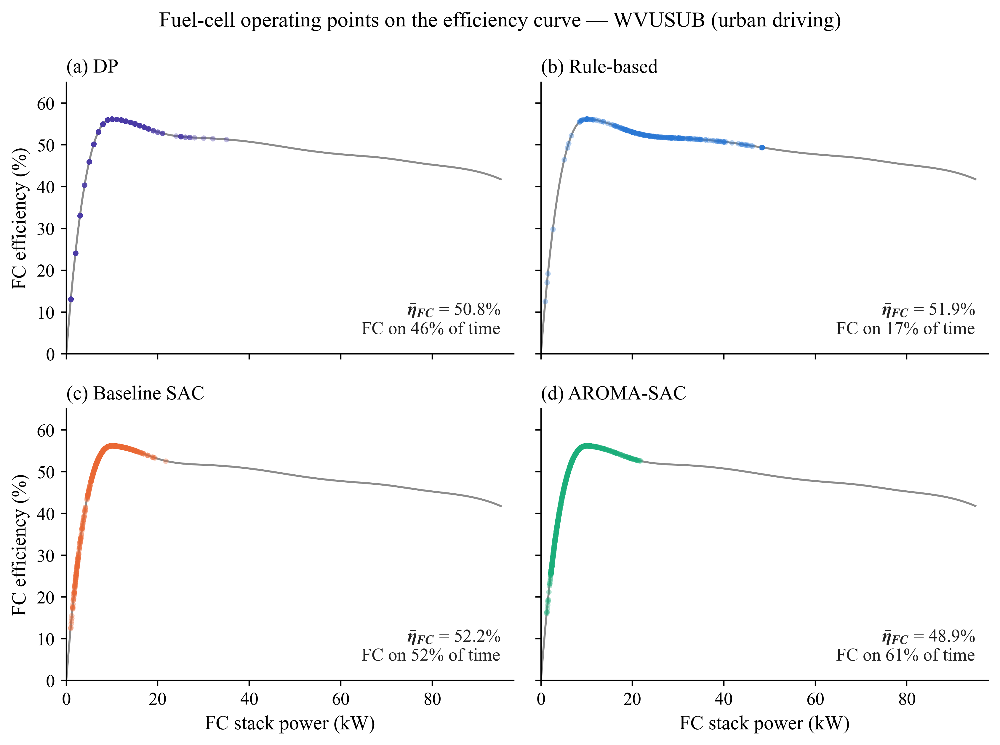

[fig] seed1_gpt_iter3__figS3_fc_operating_points_seed1_LA92 -> paper_figures/


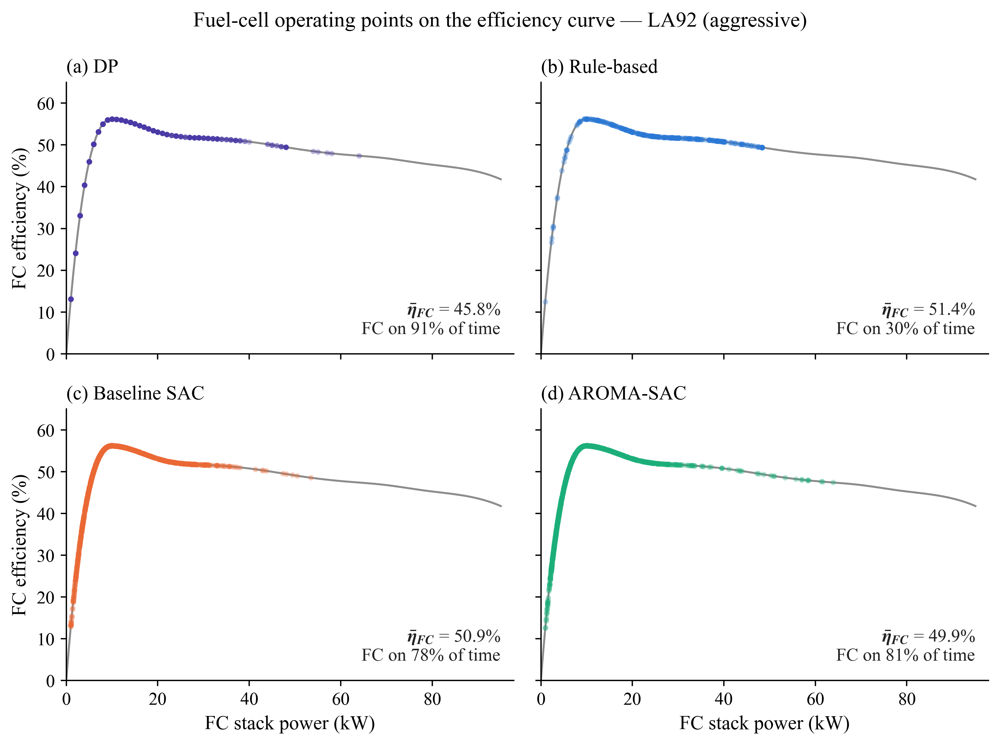

[fig] seed1_gpt_iter3__figS4_fc_operating_points_seed1_HWFET -> paper_figures/


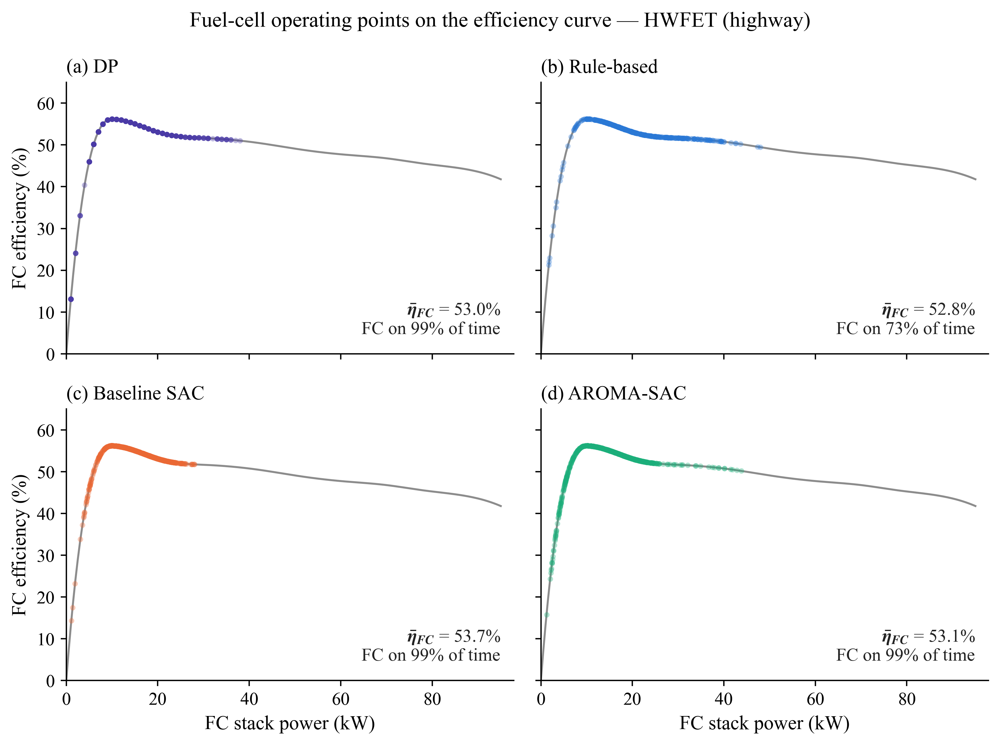

In [13]:
print(f'Figures S1-S4: seed {SEED}, AROMA-SAC = GPT run iteration {POLICIES["AROMA-SAC"][0]} ({POLICIES["AROMA-SAC"][2]})')


def fc_operating_points_figure(cycle, number):
    tr = eval_traces(cycle)
    fig, axes = plt.subplots(2, 2, figsize=(8.6, 6.4), sharex=True, sharey=True)
    for ax, tag, (m, title) in zip(axes.ravel(), 'abcd', FC_PANELS):
        p, eff, trip_eff, on_pct = fc_operating_points(tr[m])
        ax.plot(FC_CURVE_P, FC_CURVE_EFF, color='0.55', linewidth=1.2, zorder=1)
        ax.scatter(p, eff, s=11, color=STYLE[m]['color'], alpha=0.35, linewidths=0, zorder=2)
        ax.text(0.97, 0.06, f'$\\bar{{\\eta}}_{{FC}}$ = {trip_eff:.1f}%\nFC on {on_pct:.0f}% of time', transform=ax.transAxes,
                ha='right', va='bottom', fontsize=11, color=INK)
        ax.set_xlim(0, FC_CURVE_P.max() * 1.03)
        ax.set_ylim(0, 65)
        ax.set_title(f'({tag}) {title}', loc='left', fontsize=12)
    for ax in axes[-1]:
        ax.set_xlabel('FC stack power (kW)')
    for ax in axes[:, 0]:
        ax.set_ylabel('FC efficiency (%)')
    fig.suptitle(f'Fuel-cell operating points on the efficiency curve — {cycle} ({CYCLE_CLASS[cycle]})', fontsize=13)
    fig.tight_layout()
    save_fig(f'figS{number}_fc_operating_points_seed{SEED}_{cycle}', fig)
    plt.show()


for k, c in enumerate(CYCLES, start=1):
    fc_operating_points_figure(c, k)